In [3]:
pip install networkx

   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---------------------------------------- 2.1/2.1 MB 19.3 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


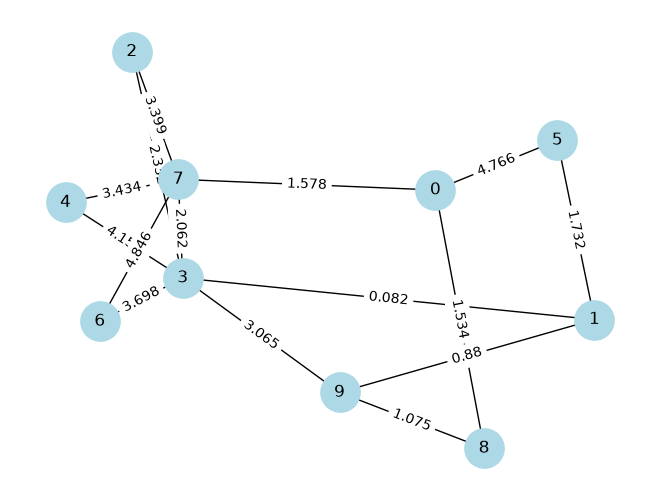

In [4]:
import networkx as nx #You may need to install this using pip install networkx
import random

def random_graph(n, m, max_weight=10):
    # Create an empty undirected graph
    G = nx.Graph()

    # Add n vertices
    G.add_nodes_from(range(n))

    # Generate all possible edges
    possible_edges = [
        (u, v)
        for u in range(n)
        for v in range(u + 1, n)
    ]

    # Make sure there aren't more edges than possible
    if m > len(possible_edges):
        raise ValueError("Too many edges for the given number of vertices.")

    # Randomly select m distinct edges
    edges = random.sample(possible_edges, m)

    # Assign each edge a random nonnegative weight
    for u, v in edges:
        weight = random.uniform(0, max_weight)
        G.add_edge(u, v, weight=weight)

    return G

G = random_graph(10, 15, 5) #Use this to generate the graph. The formula is (Number on nodes, Number of Edges, Max weight of all edges).

import matplotlib.pyplot as plt #We need this to draw the graph.

pos = nx.spring_layout(G) #This edits the layout for the graph.

nx.draw(
    G,
    pos,
    with_labels=True,
    node_color='lightblue',
    node_size=800
)

# Display edge weights
edge_labels = nx.get_edge_attributes(G, 'weight') #You can shorten the weight values by using round(edge_labels, 2) to round the weights to 2 decimal places.
rounded_labels = {edge: round(weight, 3) for edge, weight in edge_labels.items()}
nx.draw_networkx_edge_labels(G, pos, edge_labels=rounded_labels)

plt.show()

Shortest distances from vertex 0:
  0 -> 0: 0.000
  0 -> 1: 0.789
  0 -> 2: 3.888
  0 -> 3: 4.377
  0 -> 4: 3.969
  0 -> 5: 7.464
  0 -> 6: 4.657
  0 -> 7: 2.405
  0 -> 8: 4.107
  0 -> 9: 5.732
Shortest path from 0 to 9: [0, 1, 3, 9]
Total weight of the path: 5.732


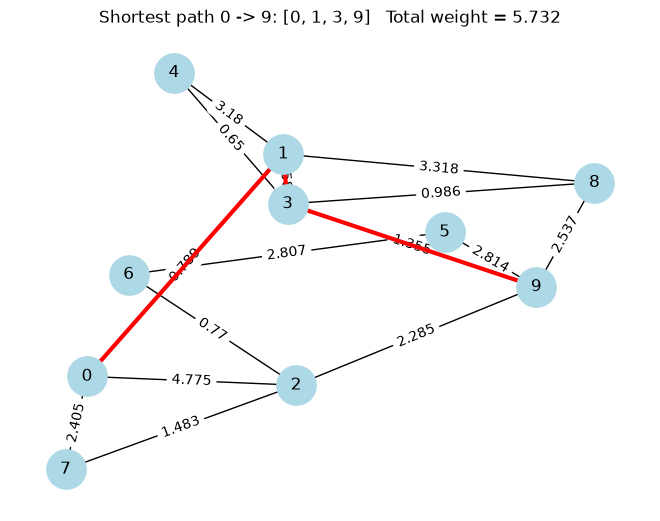

In [5]:
import heapq #needed for heappush and heappop
from math import inf #needed for infinity
import networkx as nx #needed for developing the graphs
import random #randomizes the inputs for the graphs
# Dijkstra's algorithm
def dijkstra(graph, s):
    """
    Shortest paths from source s in a graph with non-negative edge weights.
    graph: dict mapping each vertex to a list of (neighbor, weight) pairs.
    s:     the source vertex.
    Returns (dist, parent):
      dist[v]   = length of the shortest path from s to v (inf if unreachable)
      parent[v] = vertex just before v on a shortest path (None for s / unreachable)
    """
    # Tentative distance for every vertex: 0 for s, infinity for the rest.
    dist = {v: inf for v in graph}
    parent = {v: None for v in graph}
    dist[s] = 0

    done = set()              # "finished" vertices, whose distance is final
    heap = [(0, s)]           # priority queue of (tentative distance, vertex)

    while heap:
        d, u = heapq.heappop(heap)    # closest vertex not yet finished
        if u in done:                 # stale entry: u was already finished
            continue
        done.add(u)                   # mark u as finished
        # Check whether going through u gives a shorter route to a neighbor.
        for v, w in graph[u]:
            if v not in done and d + w < dist[v]:
                dist[v] = d + w
                parent[v] = u
                heapq.heappush(heap, (dist[v], v))
    return dist, parent

def shortest_path(parent, s, t):
    """Rebuild the path from s to t using the parent pointers."""
    path = []
    v = t
    while v is not None:
        path.append(v)
        v = parent[v]
    path.reverse()
    return path if path and path[0] == s else []   # [] if t is unreachable

# Random graph code
def random_graph(n, m, max_weight=10):
    # Create an empty undirected graph
    G = nx.Graph()
    # Add n vertices
    G.add_nodes_from(range(n))
    # Generate all possible edges
    possible_edges = [
        (u, v)
        for u in range(n)
        for v in range(u + 1, n)
    ]
    # Make sure there aren't more edges than possible
    if m > len(possible_edges):
        raise ValueError("Too many edges for the given number of vertices.")
    # Randomly select m distinct edges
    edges = random.sample(possible_edges, m)
    # Assign each edge a random nonnegative weight
    for u, v in edges:
        weight = random.uniform(0, max_weight)
        G.add_edge(u, v, weight=weight)
    return G
G = random_graph(10, 15, 5) #Use this to generate the graph. The formula is (Number on nodes, Number of Edges, Max weight of all edges).

# Running Dijkstra on the random graph
# Convert the networkx graph into the adjacency-list dict that dijkstra() expects.
graph = {u: [(v, G[u][v]["weight"]) for v in G[u]] for u in G}

s, t = 0, 9   # source vertex and target vertex (change these as you like)
dist, parent = dijkstra(graph, s)
path = shortest_path(parent, s, t)

print(f"Shortest distances from vertex {s}:")
for v in sorted(dist):
    print(f"  {s} -> {v}: {dist[v]:.3f}")
if path:
    total_weight = dist[t]
    print(f"Shortest path from {s} to {t}: {path}")
    print(f"Total weight of the path: {total_weight:.3f}")
    title = f"Shortest path {s} -> {t}: {path}   Total weight = {total_weight:.3f}"
else:
    print(f"No path from {s} to {t} in this graph.")
    title = f"No path from {s} to {t} in this graph"

# Draw the graph (shortest path in red)
import matplotlib.pyplot as plt #We need this to draw the graph.
pos = nx.spring_layout(G) #This edits the layout for the graph.
nx.draw(G,pos,with_labels=True,node_color='lightblue',node_size=800)

# Display edge weights
edge_labels = nx.get_edge_attributes(G, 'weight') #You can shorten the weight values by using round(edge_labels, 2) to round the weights to 2 decimal places.
rounded_labels = {edge: round(weight, 3) for edge, weight in edge_labels.items()}
nx.draw_networkx_edge_labels(G, pos, edge_labels=rounded_labels)

# Highlight the shortest path found by Dijkstra's algorithm
nx.draw_networkx_edges(G, pos, edgelist=list(zip(path, path[1:])),edge_color="red", width=3)
plt.title(title)   # shows the path and its total weight above the graph

plt.show()

Shortest path 0 -> 9: [0, 1, 3, 9]   Total weight = 5.732


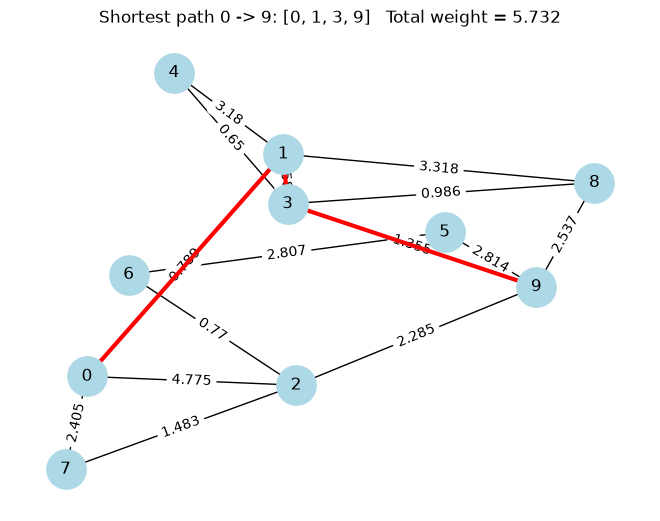

In [8]:
import heapq, math
from math import inf
import networkx as nx
import matplotlib.pyplot as plt

def duan_sssp(graph, s):
    n = len(graph)
    lg = max(math.log2(n), 1.0)
    k = max(1, int(lg ** (1 / 3)))
    t = max(1, int(lg ** (2 / 3)))
    top = math.ceil(lg / t)
    db = {v: inf for v in graph}; db[s] = 0
    pred = {v: None for v in graph}; pw = {v: 0 for v in graph}

    def relax(u, v, w, nd):
        if nd < db[v]:
            pred[v], pw[v] = u, w
        db[v] = nd

    def base_case(B, S):                               # Algorithm 2
        x = S[0]; heap = [(db[x], x)]; done = set()
        while heap and len(done) < k + 1:
            d, u = heapq.heappop(heap)
            if u in done or d != db[u]: continue
            done.add(u)
            for v, w in graph[u]:
                nd = db[u] + w
                if nd <= db[v] and nd < B:
                    relax(u, v, w, nd); heapq.heappush(heap, (nd, v))
        if len(done) <= k: return B, done
        Bp = max(db[v] for v in done)
        return Bp, {v for v in done if db[v] < Bp}

    def find_pivots(B, S):                             # Algorithm 1
        W, prev = set(S), set(S)
        for _ in range(k):
            cur = set()
            for u in prev:
                for v, w in graph[u]:
                    nd = db[u] + w
                    if nd <= db[v]:
                        relax(u, v, w, nd)
                        if nd < B: cur.add(v)
            W |= cur
            if len(W) > k * len(S): return list(S), W
            prev = cur
        kids, has_parent = {}, set()
        for v in W:
            p = pred[v]
            if p is not None and p in W and db[v] == db[p] + pw[v]:
                kids.setdefault(p, []).append(v); has_parent.add(v)
        P = []
        for u in S:
            if u in has_parent: continue
            size, stack = 0, [u]
            while stack:
                y = stack.pop(); size += 1; stack.extend(kids.get(y, []))
            if size >= k: P.append(u)
        return P, W

    def bmssp(l, B, S):                                # Algorithm 3
        if l == 0: return base_case(B, S)
        P, W = find_pivots(B, S)
        M = 2 ** ((l - 1) * t)
        best, heap = {}, []                            # simplified data structure D
        def insert(key, val):
            if key not in best or val < best[key]:
                best[key] = val; heapq.heappush(heap, (val, key))
        def pull():
            keys = []
            while heap and len(keys) < M:
                val, key = heapq.heappop(heap)
                if best.get(key) == val: del best[key]; keys.append(key)
            while heap and best.get(heap[0][1]) != heap[0][0]: heapq.heappop(heap)
            return (heap[0][0] if heap else B), keys
        for x in P: insert(x, db[x])
        Bp_i = min((db[x] for x in P), default=B)
        U, limit = set(), k * 2 ** (l * t)
        while len(U) < limit and best:
            Bi, Si = pull()
            Bp_i, Ui = bmssp(l - 1, Bi, Si)
            U |= Ui
            K = []
            for u in Ui:
                for v, w in graph[u]:
                    nd = db[u] + w
                    if nd <= db[v]:
                        relax(u, v, w, nd)
                        if Bi <= nd < B: insert(v, nd)
                        elif Bp_i <= nd < Bi: K.append((v, nd))
            K += [(x, db[x]) for x in Si if Bp_i <= db[x] < Bi]
            for key, val in K: insert(key, val)
        Bp = B if not best else min(Bp_i, B)
        return Bp, U | {x for x in W if db[x] < Bp}

    bmssp(top, inf, [s])
    return db, pred

# ---------- Run it on the existing graph G and draw the result ----------
graph = {u: [(v, G[u][v]["weight"]) for v in G[u]] for u in G}   # s and t come from your earlier cell

dist2, parent2 = duan_sssp(graph, s)
path2, v = [], t
while v is not None:
    path2.append(v); v = parent2[v]
path2.reverse()
if path2[0] != s: path2 = []

if path2:
    title = f"Shortest path {s} -> {t}: {path2}   Total weight = {dist2[t]:.3f}"
else:
    title = f"No path from {s} to {t}"
print(title)

if 'pos' not in globals():
    pos = nx.spring_layout(G)
nx.draw(G, pos, with_labels=True, node_color='lightblue', node_size=800)
labels = {e: round(w, 3) for e, w in nx.get_edge_attributes(G, 'weight').items()}
nx.draw_networkx_edge_labels(G, pos, edge_labels=labels)
nx.draw_networkx_edges(G, pos, edgelist=list(zip(path2, path2[1:])), edge_color="red", width=3)
plt.title(title)
plt.show()